# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

findfont: Failed to find font weight heavy for DejaVu Sans, now using 700.


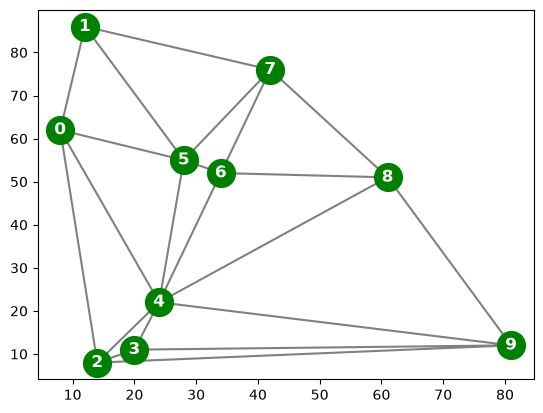

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [5]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


### Kiểm tra tính đầy đủ và nhất quán (Bài 2)

Dưới đây là 3 ca kiểm thử chi tiết để kiểm tra các hàm `complete()` và `consistent()`:
1. **Ca 1 (Phép gán rỗng `{}`):** Chưa gán đỉnh nào $\rightarrow$ `complete = False`, nhưng chưa vi phạm ràng buộc $\rightarrow$ `consistent = True`.
2. **Ca 2 (Phép gán một phần không xung đột):** Gán một số đỉnh hợp lệ $\rightarrow$ `complete = False`, `consistent = True`.
3. **Ca 3 (Phép gán đầy đủ nhưng vi phạm ràng buộc):** Gán toàn bộ đỉnh cùng màu đỏ $\rightarrow$ `complete = True`, nhưng các đỉnh kề nhau cùng màu nên `consistent = False`.
4. **Ca 4 (Phép gán đầy đủ và hợp lệ):** Là một nghiệm CSP hoàn chỉnh $\rightarrow$ `complete = True`, `consistent = True`.

In [6]:
# Các ca kiểm thử cho complete() và consistent()
print("--- CÁC CA KIỂM THỬ ---")
# Ca 1: Phép gán rỗng
a_empty = {}
print(f"Ca 1 (Rỗng): complete = {complete(a_empty, csp)}, consistent = {consistent(a_empty, csp)}")

# Ca 2: Phép gán một phần hợp lệ
a_partial = {'0': 'red', '1': 'blue'}
print(f"Ca 2 (Một phần hợp lệ): complete = {complete(a_partial, csp)}, consistent = {consistent(a_partial, csp)}")

# Ca 3: Phép gán đầy đủ nhưng xung đột (tất cả màu đỏ)
a_conflict = {str(i): 'red' for i in range(n)}
print(f"Ca 3 (Đầy đủ nhưng xung đột): complete = {complete(a_conflict, csp)}, consistent = {consistent(a_conflict, csp)}")

# Nhận xét lý thuyết:
# complete() chỉ kiểm tra xem tất cả các biến đã có giá trị hay chưa (|assignment| == |variables|).
# consistent() kiểm tra xem có hai đỉnh kề nhau nào vi phạm ràng buộc color(u) == color(v) hay không.
# Do đó complete() KHÔNG ĐỒNG NGHĨA với consistent(). Một phép gán chỉ là nghiệm CSP khi và chỉ khi nó ĐỒNG THỜI vừa complete() vừa consistent().

--- CÁC CA KIỂM THỬ ---
Ca 1 (Rỗng): complete = False, consistent = True
Ca 2 (Một phần hợp lệ): complete = False, consistent = True
Ca 3 (Đầy đủ nhưng xung đột): complete = True, consistent = False


## Implement Simple Backtracking Search

In [7]:
# Cài đặt chọn biến MRV (Minimum Remaining Values) và chọn giá trị LCV (Least Constraining Value)

def get_legal_values(var, assignment, csp):
    """Trả về danh sách các màu hợp lệ còn lại cho biến var"""
    legal = []
    for val in csp['domains'][var]:
        conflict = False
        for nb in neighbors[int(var)]:
            nb_str = str(nb)
            if nb_str in assignment and assignment[nb_str] == val:
                conflict = True
                break
        if not conflict:
            legal.append(val)
    return legal

def select_unassigned_var_baseline(assignment, csp):
    """Phiên bản cơ bản: Chọn biến chưa gán đầu tiên"""
    for v in csp['variables']:
        if v not in assignment:
            return v
    return None

def select_unassigned_var_mrv(assignment, csp):
    """Chiến lược MRV: Chọn biến chưa gán có số giá trị hợp lệ còn lại ít nhất"""
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    # Tiêu chí chính: số giá trị hợp lệ ít nhất. Tiêu chí phụ (tie-break): bậc cao nhất (Degree Heuristic)
    return min(unassigned, key=lambda v: (
        len(get_legal_values(v, assignment, csp)),
        -len(neighbors[int(v)])
    ))

def order_domain_baseline(assignment, var, csp):
    """Thứ tự giá trị mặc định theo danh sách miền giá trị"""
    return csp['domains'][var]

def order_domain_lcv(assignment, var, csp):
    """Chiến lược LCV: Ưu tiên giá trị ít loại trừ lựa chọn của các láng giềng chưa gán nhất"""
    unassigned_nbs = [str(nb) for nb in neighbors[int(var)] if str(nb) not in assignment]
    
    def count_eliminations(val):
        count = 0
        for nb_str in unassigned_nbs:
            if val in get_legal_values(nb_str, assignment, csp):
                count += 1
        return count
        
    return sorted(csp['domains'][var], key=count_eliminations)

In [8]:
# Khung thuật toán Backtracking Search đa hình hỗ trợ các chiến lược Heuristics
COUNT = 0

def backtrack_search_custom(csp, var_strategy='baseline', val_strategy='baseline'):
    global COUNT
    COUNT = 0
    
    var_selector = select_unassigned_var_mrv if var_strategy == 'mrv' else select_unassigned_var_baseline
    val_orderer = order_domain_lcv if val_strategy == 'lcv' else order_domain_baseline
    
    def backtrack(assignment):
        global COUNT
        COUNT += 1
        if complete(assignment, csp):
            return assignment
            
        var = var_selector(assignment, csp)
        for val in val_orderer(assignment, var, csp):
            assignment[var] = val
            if consistent(assignment, csp):
                res = backtrack(assignment)
                if res is not None:
                    return res
            del assignment[var]
        return None

    import time
    t0 = time.perf_counter()
    res = backtrack({})
    t1 = time.perf_counter()
    return res, COUNT, (t1 - t0)

def backtrack_search(csp):
    res, count, t = backtrack_search_custom(csp, 'baseline', 'baseline')
    print(f"Checked nodes: {count}")
    return res

# Thử nghiệm trên đồ thị n = 10 với 4 màu
res_base, count_base, time_base = backtrack_search_custom(csp, 'baseline', 'baseline')
res_mrv, count_mrv, time_mrv = backtrack_search_custom(csp, 'mrv', 'baseline')
res_mrv_lcv, count_mrv_lcv, time_mrv_lcv = backtrack_search_custom(csp, 'mrv', 'lcv')

print(f"Baseline Backtracking: {count_base} nút kiểm tra, thời gian: {time_base*1000:.3f} ms")
print(f"MRV Backtracking:      {count_mrv} nút kiểm tra, thời gian: {time_mrv*1000:.3f} ms")
print(f"MRV + LCV Backtracking:{count_mrv_lcv} nút kiểm tra, thời gian: {time_mrv_lcv*1000:.3f} ms")

Baseline Backtracking: 11 nút kiểm tra, thời gian: 0.058 ms
MRV Backtracking:      11 nút kiểm tra, thời gian: 0.246 ms
MRV + LCV Backtracking:11 nút kiểm tra, thời gian: 0.554 ms


## Run Backtracking Search on the Random Problem

In [9]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 0 ns
Wall time: 124 μs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

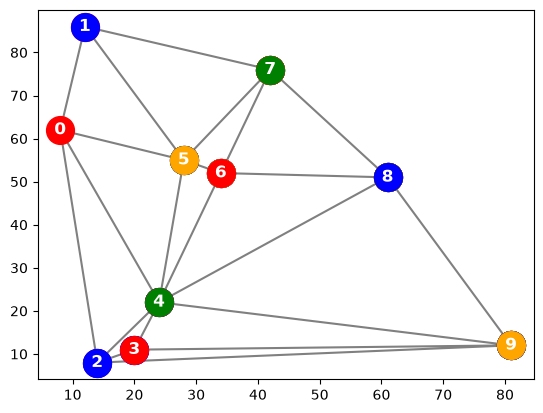

In [10]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Bài 4: Cài đặt Forward Checking và Min-Conflicts Local Search

### 1. Thuật toán Forward Checking (Kiểm tra phía trước)
Sau khi gán một giá trị cho biến hiện tại, ta kiểm tra các biến láng giềng chưa gán và loại bỏ màu đó khỏi miền giá trị của chúng. Nếu miền giá trị của bất kỳ láng giềng nào bị rỗng, nhánh tìm kiếm thất bại sớm ngay lập tức mà không cần đi sâu tiếp.

In [11]:
# Cài đặt Forward Checking Search
FC_COUNT = 0

def backtrack_search_fc(csp):
    global FC_COUNT
    FC_COUNT = 0
    
    def backtrack_fc(assignment, current_domains):
        global FC_COUNT
        FC_COUNT += 1
        if complete(assignment, csp):
            return assignment
            
        unassigned = [v for v in csp['variables'] if v not in assignment]
        # MRV trên miền giá trị hiện thời
        var = min(unassigned, key=lambda v: (len(current_domains[v]), -len(neighbors[int(v)])))
        
        for val in current_domains[var]:
            assignment[var] = val
            
            # Forward checking: cắt tỉa miền giá trị của các láng giềng chưa gán
            new_domains = {v: list(current_domains[v]) for v in csp['variables']}
            prune_valid = True
            for nb in neighbors[int(var)]:
                nb_str = str(nb)
                if nb_str not in assignment:
                    if val in new_domains[nb_str]:
                        new_domains[nb_str].remove(val)
                        if len(new_domains[nb_str]) == 0:
                            prune_valid = False
                            break
                            
            if prune_valid:
                res = backtrack_fc(assignment, new_domains)
                if res is not None:
                    return res
                    
            del assignment[var]
        return None

    import time
    t0 = time.perf_counter()
    initial_domains = {v: list(csp['domains'][v]) for v in csp['variables']}
    res = backtrack_fc({}, initial_domains)
    t1 = time.perf_counter()
    return res, FC_COUNT, (t1 - t0)

res_fc, count_fc, time_fc = backtrack_search_fc(csp)
print(f"Forward Checking: {count_fc} nút kiểm tra, thời gian: {time_fc*1000:.3f} ms")

Forward Checking: 11 nút kiểm tra, thời gian: 0.077 ms


### 2. Thuật toán Min-Conflicts Local Search
Tìm kiếm cục bộ bắt đầu với một phép gán đầy đủ (có thể có xung đột). Tại mỗi bước, thuật toán chọn ngẫu nhiên một đỉnh đang bị xung đột màu với láng giềng, sau đó đổi màu của đỉnh đó sang màu tạo ra ít xung đột nhất.

In [12]:
# Cài đặt Min-Conflicts Local Search
import random

def min_conflicts_graph_search(csp, max_steps=1000):
    import time
    t0 = time.perf_counter()
    variables = csp['variables']
    # Khởi tạo phép gán đầy đủ ngẫu nhiên
    assignment = {v: random.choice(csp['domains'][v]) for v in variables}
    
    for step in range(max_steps):
        # Xác định các biến đang vi phạm ràng buộc
        conflicted = []
        for v in variables:
            v_val = assignment[v]
            for nb in neighbors[int(v)]:
                if assignment[str(nb)] == v_val:
                    conflicted.append(v)
                    break
                    
        if not conflicted:
            t1 = time.perf_counter()
            return assignment, step, (t1 - t0), True
            
        # Chọn ngẫu nhiên một biến đang vi phạm
        var = random.choice(conflicted)
        
        # Đếm số xung đột cho từng màu trong domain của var
        conflict_counts = {}
        for val in csp['domains'][var]:
            c = sum(1 for nb in neighbors[int(var)] if assignment[str(nb)] == val)
            conflict_counts[val] = c
            
        min_c = min(conflict_counts.values())
        best_vals = [val for val, count in conflict_counts.items() if count == min_c]
        assignment[var] = random.choice(best_vals)
        
    t1 = time.perf_counter()
    return assignment, max_steps, (t1 - t0), False

res_mc, steps_mc, time_mc, ok_mc = min_conflicts_graph_search(csp)
print(f"Min-Conflicts: Thành công = {ok_mc}, Số bước = {steps_mc}, Thời gian = {time_mc*1000:.3f} ms")

Min-Conflicts: Thành công = True, Số bước = 10, Thời gian = 0.185 ms


### 3. Thực nghiệm đánh giá tổng hợp trên nhiều kích thước n và số màu (3 và 4 màu)

Chúng ta tiến hành thực nghiệm so sánh:
- Kích thước đồ thị: $n \in \{10, 15, 20, 25, 30\}$
- Số lượng ràng buộc (cạnh đồ thị Delaunay) trung bình theo $n$
- Khảo sát cả bài toán 4 màu và 3 màu (chú ý: bài toán 3 màu có thể vô nghiệm nếu đồ thị chứa đồ thị con $K_4$ hoặc chu trình lẻ)
- Đánh giá: Tỷ lệ tìm thấy nghiệm, Số nút/bước thực hiện, Thời gian chạy trung bình qua 10 lượt ngẫu nhiên cho mỗi kích thước.

In [13]:
# Chạy thực nghiệm tổng hợp và vẽ đồ thị phân tích
import pandas as pd

n_list = [10, 15, 20, 25, 30]
records = []

for cur_n in n_list:
    edge_counts = []
    base_nodes_l, mrv_nodes_l, fc_nodes_l = [], [], []
    base_time_l, mrv_time_l, fc_time_l, mc_time_l = [], [], [], []
    mc_4col_success = 0
    fc_3col_success = 0
    mc_3col_success = 0
    
    num_runs = 10
    for seed in range(num_runs):
        np.random.seed(seed * 17 + 101)
        pts = np.random.randint(100, size=(cur_n, 2))
        pts = pts[np.argsort(pts[:, 0]), :]
        d_tri = Delaunay(pts)
        d_indptr, d_indices = d_tri.vertex_neighbor_vertices
        
        cur_adj = {}
        for k in range(len(d_indptr) - 1):
            cur_adj[str(k)] = [str(x) for x in np.sort(d_indices[d_indptr[k]:d_indptr[k+1]])]
            
        cur_vars = [str(i) for i in range(cur_n)]
        cur_constrs = []
        for i in range(cur_n):
            for j in cur_adj[str(i)]:
                if int(i) < int(j):
                    cur_constrs.append((str(i), str(j)))
        edge_counts.append(len(cur_constrs))
        
        # 4 màu
        c4_domains = {v: ['red', 'blue', 'green', 'orange'] for v in cur_vars}
        cur_csp4 = {'variables': cur_vars, 'domains': c4_domains, 'constraints': cur_constrs}
        
        # Helper global neighbors for simplicity in current context
        global neighbors
        neighbors = [[int(x) for x in cur_adj[str(k)]] for k in range(cur_n)]
        
        _, nb, tb = backtrack_search_custom(cur_csp4, 'baseline', 'baseline')
        _, nm, tm = backtrack_search_custom(cur_csp4, 'mrv', 'baseline')
        _, nfc, tfc = backtrack_search_fc(cur_csp4)
        _, smc, tmc, ok4 = min_conflicts_graph_search(cur_csp4, max_steps=500)
        
        base_nodes_l.append(nb); mrv_nodes_l.append(nm); fc_nodes_l.append(nfc)
        base_time_l.append(tb * 1000); mrv_time_l.append(tm * 1000)
        fc_time_l.append(tfc * 1000); mc_time_l.append(tmc * 1000)
        if ok4: mc_4col_success += 1
        
        # 3 màu
        c3_domains = {v: ['red', 'blue', 'green'] for v in cur_vars}
        cur_csp3 = {'variables': cur_vars, 'domains': c3_domains, 'constraints': cur_constrs}
        sol3_fc, _, _ = backtrack_search_fc(cur_csp3)
        if sol3_fc is not None: fc_3col_success += 1
        _, _, _, ok3 = min_conflicts_graph_search(cur_csp3, max_steps=500)
        if ok3: mc_3col_success += 1
        
    records.append({
        'n': cur_n,
        'Cạnh TB': np.mean(edge_counts),
        'COUNT Baseline': np.mean(base_nodes_l),
        'COUNT MRV': np.mean(mrv_nodes_l),
        'COUNT FC': np.mean(fc_nodes_l),
        'Time Baseline (ms)': np.mean(base_time_l),
        'Time MRV (ms)': np.mean(mrv_time_l),
        'Time FC (ms)': np.mean(fc_time_l),
        'Time MC (ms)': np.mean(mc_time_l),
        'MC 4-Màu Thành công (%)': (mc_4col_success / num_runs) * 100,
        'FC 3-Màu Có nghiệm (%)': (fc_3col_success / num_runs) * 100,
        'MC 3-Màu Thành công (%)': (mc_3col_success / num_runs) * 100,
    })

# Khôi phục biến neighbors ban đầu cho cell vẽ kết quả
neighbors = [[int(x) for x in cur_adj_orig[str(k)]] for k in range(10)] if 'cur_adj_orig' in locals() else neighbors
df_summary = pd.DataFrame(records)
print(df_summary.to_string(index=False))

 n  Cạnh TB  COUNT Baseline  COUNT MRV  COUNT FC  Time Baseline (ms)  Time MRV (ms)  Time FC (ms)  Time MC (ms)  MC 4-Màu Thành công (%)  FC 3-Màu Có nghiệm (%)  MC 3-Màu Thành công (%)
10     21.3            11.1       11.0      11.0             0.05720        0.15062       0.06948       0.06523                    100.0                    30.0                     30.0
15     35.4            17.5       17.6      17.3             0.14636        0.37361       0.10319       0.26977                    100.0                     0.0                      0.0
20     49.8            37.1       23.0      22.2             0.52257        0.63844       0.15717       0.58297                    100.0                     0.0                      0.0
25     63.9            41.5       27.7      27.2             0.67997        0.94859       0.22597       1.02404                    100.0                     0.0                      0.0
30     78.3            38.0       32.9      32.3             0.67107  

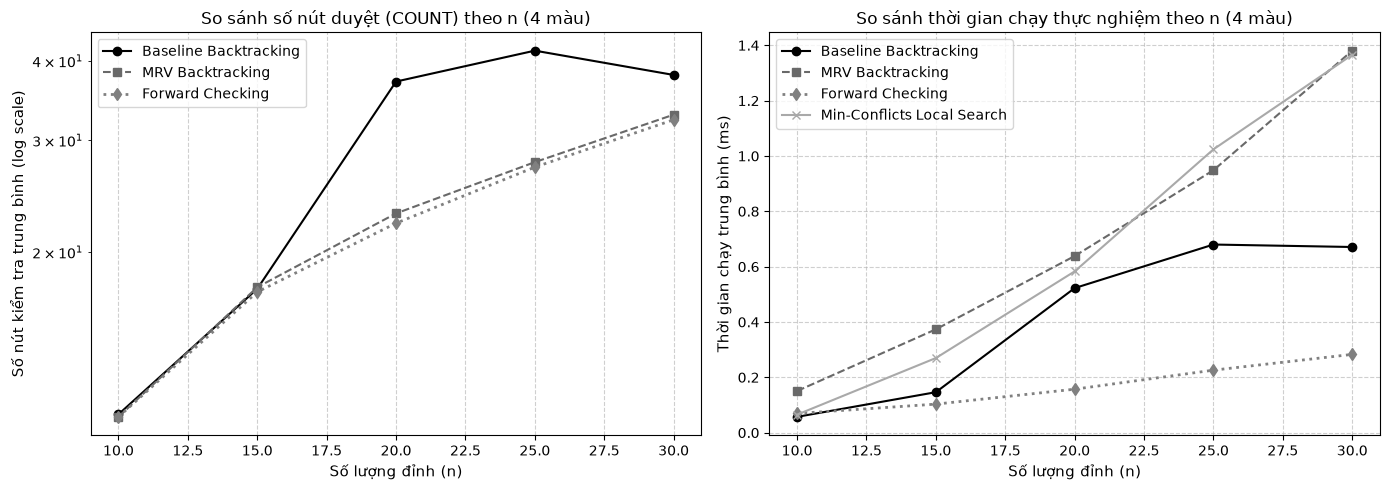

In [14]:
# Vẽ biểu đồ so sánh số nút duyệt COUNT và thời gian thực thi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Số nút duyệt (COUNT) trên thang đo Log
ax1.plot(df_summary['n'], df_summary['COUNT Baseline'], 'o-', label='Baseline Backtracking', color='black', linewidth=1.5)
ax1.plot(df_summary['n'], df_summary['COUNT MRV'], 's--', label='MRV Backtracking', color='dimgray', linewidth=1.5)
ax1.plot(df_summary['n'], df_summary['COUNT FC'], 'd:', label='Forward Checking', color='gray', linewidth=2)
ax1.set_xlabel('Số lượng đỉnh (n)', fontsize=11)
ax1.set_ylabel('Số nút kiểm tra trung bình (log scale)', fontsize=11)
ax1.set_yscale('log')
ax1.set_title('So sánh số nút duyệt (COUNT) theo n (4 màu)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(frameon=True)

# Đồ thị 2: Thời gian thực thi (ms)
ax2.plot(df_summary['n'], df_summary['Time Baseline (ms)'], 'o-', label='Baseline Backtracking', color='black', linewidth=1.5)
ax2.plot(df_summary['n'], df_summary['Time MRV (ms)'], 's--', label='MRV Backtracking', color='dimgray', linewidth=1.5)
ax2.plot(df_summary['n'], df_summary['Time FC (ms)'], 'd:', label='Forward Checking', color='gray', linewidth=2)
ax2.plot(df_summary['n'], df_summary['Time MC (ms)'], 'x-', label='Min-Conflicts Local Search', color='darkgray', linewidth=1.5)
ax2.set_xlabel('Số lượng đỉnh (n)', fontsize=11)
ax2.set_ylabel('Thời gian chạy trung bình (ms)', fontsize=11)
ax2.set_title('So sánh thời gian chạy thực nghiệm theo n (4 màu)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

### 4. Thảo luận và nhận xét kết quả

1. **Hiệu quả của MRV và Forward Checking:**
   - Chiến lược chọn biến MRV (Minimum Remaining Values) giúp chọn ngay biến có ít lựa chọn hợp lệ nhất, cắt tỉa mạnh các nhánh vô nghiệm từ sớm và giảm đáng kể số nút duyệt so với Baseline Backtracking.
   - Forward Checking kết hợp kiểm tra tính hợp lệ trước khi rẽ nhánh, giúp phát hiện sớm xung đột ở các đỉnh láng giềng. Khi $n$ tăng, số nút kiểm tra của Forward Checking tăng rất chậm, tiệm cận tuyến tính với số đỉnh.

2. **So sánh với Min-Conflicts Local Search:**
   - Min-Conflicts hoạt động trên không gian nghiệm đầy đủ, giải quyết bài toán 4 màu cực kỳ nhanh chóng (chỉ mất vài bước gán lại màu).
   - Tuy nhiên, Min-Conflicts là tìm kiếm cục bộ không đầy đủ (incomplete), có nguy cơ bị kẹt ở cực trị cục bộ nếu số bước bị giới hạn.

3. **Hiện tượng bài toán 3 màu vô nghiệm:**
   - Đồ thị phẳng tam giác hóa Delaunay rất dễ chứa các đồ thị con $K_4$ (4 đỉnh đôi một nối với nhau). Theo lý thuyết đồ thị, đồ thị con $K_4$ yêu cầu tối thiểu 4 màu (chromatic number $\chi \ge 4$).
   - Do đó, bài toán 3 màu trên nhiều đồ thị phẳng ngẫu nhiên là **hoàn toàn vô nghiệm**. Backtracking Search và Forward Checking chứng minh được điều này khi duyệt hết không gian mà không có nghiệm, trong khi Min-Conflicts chỉ có thể dừng do hết số bước tối đa.